# Exploratory Data Analysis
### Properties & Distributions of California Housing

---

### 🎯 Objectives
- **Dataset Property Discovery**: Uncover underlying census schemas, feature distributions, missing value patterns, and right-censored survey caps (52 years and $500,001).
- **Geospatial & Correlation Structure**: Analyze non-linear geographical pricing clusters, multicollinearity, and formulate domain feature engineering ratios for ML modeling.

---

### 📋 Scope of Work
This notebook executes the following structured exploratory workflow:
1. **Imports & Environment Setup**: Package imports, styling configuration, and font handling.
2. **Dataset Ingestion**: Data loading (`data/dataset.csv`) and sample record preview.
3. **Schema & Data Integrity Audit**: Automated profiling of data types, null counts, cardinality, and sample values.
4. **Descriptive Statistics & Skewness**: Parametric moments, quantile spreads, skewness, and kurtosis metrics.
5. **Categorical Feature Analysis (`ocean_proximity`)**:
   - **5.1 Category Frequency**: Sample counts, percentage shares, and class imbalance.
   - **5.2 Price Stratification**: House value distributions and coastal premiums via boxplots.
6. **Numerical Feature Distributions**: 50-bin histograms diagnosing skewness, multimodal peaks, and boundary caps.
7. **Geospatial & Coordinate Mapping**: High-resolution geographical scatter mapping of population and price clusters.
8. **Target Censoring Analysis**: Deep-dive into right-censored ceiling caps at $500,001 and distribution clipping.
9. **Correlation Structure & Multicollinearity**: Pearson correlation matrix and heatmaps identifying primary predictive drivers.
10. **Domain Feature Engineering**: Formulating household and room density ratios with correlation impact analysis.
11. **Engineering Takeaways & ML Guidelines**: Practical preprocessing and model architecture recommendations.

---

## 1. Imports & Environment Setup
- **Library Ingestion**: Imports core data analysis and visualization packages (`numpy`, `pandas`, `matplotlib`, `seaborn`).
- **Styling Configuration**: Sets clean visualization themes, figure resolution, and font sizing.
- **Warning Suppression**: Silences font fallback notifications to ensure clean visual diagnostics.

In [1]:
import os
import sys
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plotting style and font manager
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
plt.rcParams["mathtext.fontset"] = "dejavusans"
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.size"] = 11
plt.rcParams["figure.dpi"] = 120

print(f"Python: {sys.version.split()[0]} | Pandas: {pd.__version__} | NumPy: {np.__version__}")

Python: 3.12.3 | Pandas: 3.0.6 | NumPy: 2.5.3


## 2. Dataset Ingestion
- **Data Loading**: Ingests the 1990 California Housing census dataset from `data/dataset.csv` with online fallback.
- **Shape Verification**: Confirms dataset dimensions (20,640 records across 10 raw features).
- **Record Preview**: Displays the top 5 records to inspect raw feature scales.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

candidates = [
    Path("data/dataset.csv"),
    Path("../data/dataset.csv")
]

local_path = next((p for p in candidates if p.exists()), None)
if local_path:
    print(f"Loading local dataset: {local_path.resolve()}")
    df = pd.read_csv(local_path)
else:
    print("Fetching dataset from remote URL endpoint...")
    df = pd.read_csv(DATA_URL)

print(f"Dataset successfully loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head(5)


Loading local dataset: /home/alpondith/BetaBox/python/ML/data/dataset.csv
Dataset successfully loaded: 20,640 rows, 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 3. Schema & Data Integrity Audit
- **Automated Profiling**: Programmatically extracts column data types, non-null counts, missing values, and cardinality.
- **Missingness Quantification**: Identifies missing values—isolating exactly 207 nulls in `total_bedrooms` (1.003% of data).
- **Value Inspection**: Samples concrete row values to verify string formats and numerical scales without manual hardcoding.

In [3]:
profile_df = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null Count": df.notnull().sum(),
    "Missing Count": df.isnull().sum(),
    "Missing (%)": (df.isnull().mean() * 100).round(2),
    "Cardinality": df.nunique(),
    "Sample Value": df.iloc[0].values
})

print(f"Total Records: {len(df):,} | Features: {df.shape[1]} | Memory: {df.memory_usage(deep=True).sum() / 1024:.1f} KB")
profile_df

Total Records: 20,640 | Features: 10 | Memory: 2601.6 KB


,Data Type,Non-Null Count,Missing Count,Missing (%),Cardinality,Sample Value
longitude,float64,20640,0,0.0,844,-122.23
latitude,float64,20640,0,0.0,862,37.88
housing_median_age,float64,20640,0,0.0,52,41.0
total_rooms,float64,20640,0,0.0,5926,880.0
total_bedrooms,float64,20433,207,1.0,1923,129.0
population,float64,20640,0,0.0,3888,322.0
households,float64,20640,0,0.0,1815,126.0
median_income,float64,20640,0,0.0,12928,8.3252
median_house_value,float64,20640,0,0.0,3842,452600.0
ocean_proximity,str,20640,0,0.0,5,NEAR BAY


## 4. Descriptive Statistics & Distribution Skewness
- **Parametric & Quantile Metrics**: Computes mean, standard deviation, quartiles, and range extremes for all numerical features.
- **Skewness & Kurtosis**: Measures distributional asymmetry to identify right-tailed volume attributes.
- **Outlier Detection**: Highlights significant spread gaps between median (50%) and maximum values.

In [4]:
stats_df = df.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
stats_df["skew"] = df.select_dtypes(include=[np.number]).skew()
stats_df["kurtosis"] = df.select_dtypes(include=[np.number]).kurtosis()

print("=== Descriptive Statistics & Distribution Moments ===")
stats_df


=== Descriptive Statistics & Distribution Moments ===


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100,-0.297801,-1.330152
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500,0.465953,-1.117760
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000,0.060331,-0.800629
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000,4.147343,32.630927
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000,3.459546,21.985575
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000,4.935858,73.553116
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000,3.410438,22.057988
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001,1.646657,4.952524
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000,0.977763,0.327870


## 5. Categorical Feature Analysis (`ocean_proximity`)
Comprehensive exploration of the single qualitative attribute in the census dataset.

### 5.1 Category Frequency & Share Distribution
- **Class Cardinality**: Assesses block group counts and percentage distribution across the 5 categories.
- **Imbalance Detection**: Highlights that `<1H OCEAN` (44.3%) and `INLAND` (31.7%) comprise over 75% of all blocks, while `ISLAND` has only 5 records.
- **Frequency Visual**: Displays frequency table and countplot bar chart.

=== Ocean Proximity Frequency & Percentage Breakdown ===
                 Block Group Count  Percentage Share (%)
ocean_proximity                                         
<1H OCEAN                     9136                 44.26
INLAND                        6551                 31.74
NEAR OCEAN                    2658                 12.88
NEAR BAY                      2290                 11.09
ISLAND                           5                  0.02


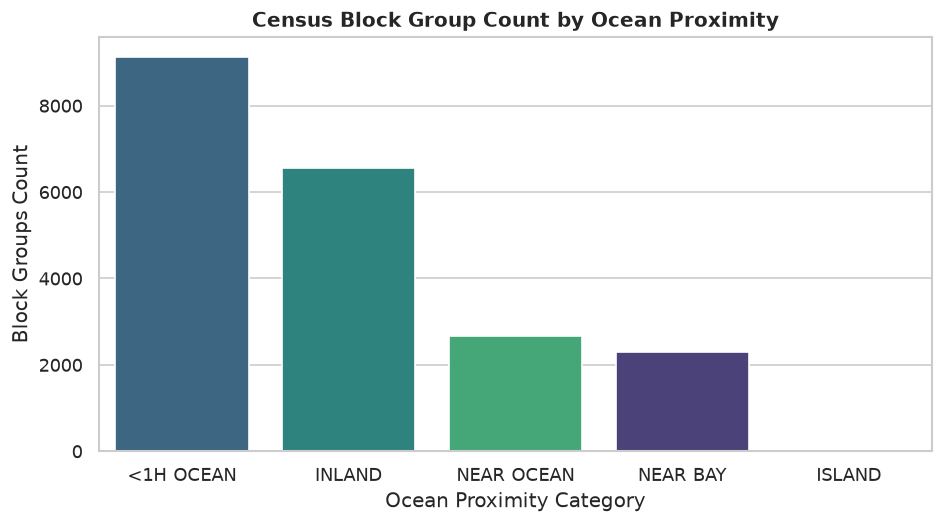

In [5]:
ocean_counts = df["ocean_proximity"].value_counts()
ocean_pct = (df["ocean_proximity"].value_counts(normalize=True) * 100).round(2)

ocean_summary = pd.DataFrame({
    "Block Group Count": ocean_counts,
    "Percentage Share (%)": ocean_pct
})

print("=== Ocean Proximity Frequency & Percentage Breakdown ===")
print(ocean_summary.to_string())

plt.figure(figsize=(8, 4.5))
sns.countplot(
    data=df,
    x="ocean_proximity",
    order=ocean_counts.index,
    hue="ocean_proximity",
    palette="viridis",
    legend=False
)
plt.title("Census Block Group Count by Ocean Proximity", fontsize=12, fontweight="bold")
plt.xlabel("Ocean Proximity Category")
plt.ylabel("Block Groups Count")
plt.tight_layout()
plt.show()

### 5.2 Price Stratification & Valuation Disparities
- **Valuation Spread**: Evaluates median, mean, and standard deviation of house values across each ocean proximity category.
- **Coastal Premium**: Demonstrates steep price premiums for coastal/bay properties (>$214k–$233k median) vs. deep inland discounts (~$108k median).
- **Distribution Diagnostics**: Boxplot visualizes interquartile ranges (IQR), medians, and ceiling truncation at $500,001.

=== Housing Valuation by Ocean Proximity ===
                 Count Median Price ($) Mean Price ($) Std Dev ($)
ocean_proximity                                                   
<1H OCEAN        9,136         $214,850       $240,084    $106,124
INLAND           6,551         $108,500       $124,805     $70,008
NEAR OCEAN       2,658         $229,450       $249,434    $122,477
NEAR BAY         2,290         $233,800       $259,212    $122,819
ISLAND               5         $414,700       $380,440     $80,560


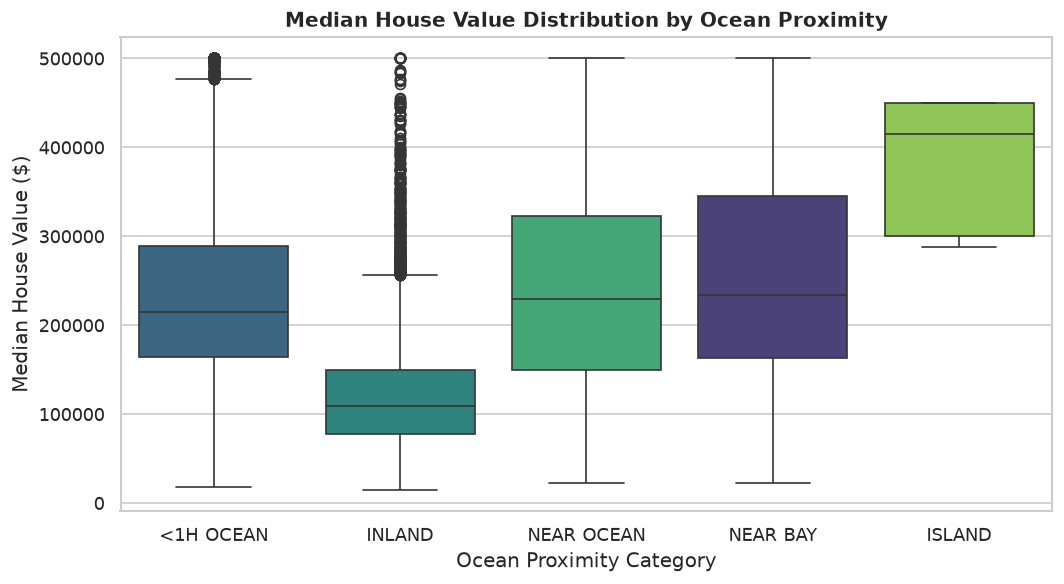

In [6]:
price_summary = df.groupby("ocean_proximity")["median_house_value"].agg(
    ["count", "median", "mean", "std"]
).loc[ocean_counts.index]

price_formatted = pd.DataFrame({
    "Count": price_summary["count"].map(lambda x: f"{x:,}"),
    "Median Price ($)": price_summary["median"].map(lambda x: f"${x:,.0f}"),
    "Mean Price ($)": price_summary["mean"].map(lambda x: f"${x:,.0f}"),
    "Std Dev ($)": price_summary["std"].map(lambda x: f"${x:,.0f}")
})

print("=== Housing Valuation by Ocean Proximity ===")
print(price_formatted.to_string())

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="ocean_proximity",
    y="median_house_value",
    order=ocean_counts.index,
    hue="ocean_proximity",
    palette="viridis",
    legend=False
)
plt.title("Median House Value Distribution by Ocean Proximity", fontsize=12, fontweight="bold")
plt.xlabel("Ocean Proximity Category")
plt.ylabel("Median House Value ($)")
plt.tight_layout()
plt.show()

## 6. Numerical Feature Distributions & Histograms
- **50-Bin Histograms**: Plots fine-grained frequency distributions for all 9 continuous numerical attributes.
- **Visual Pattern Recognition**: Identifies multimodal geographic peaks, bell-shaped economic curves, and right-tailed volume spreads.
- **Boundary Caps**: Visualizes rightmost boundary spikes in `housing_median_age` (52 years) and `median_house_value` ($500,001).

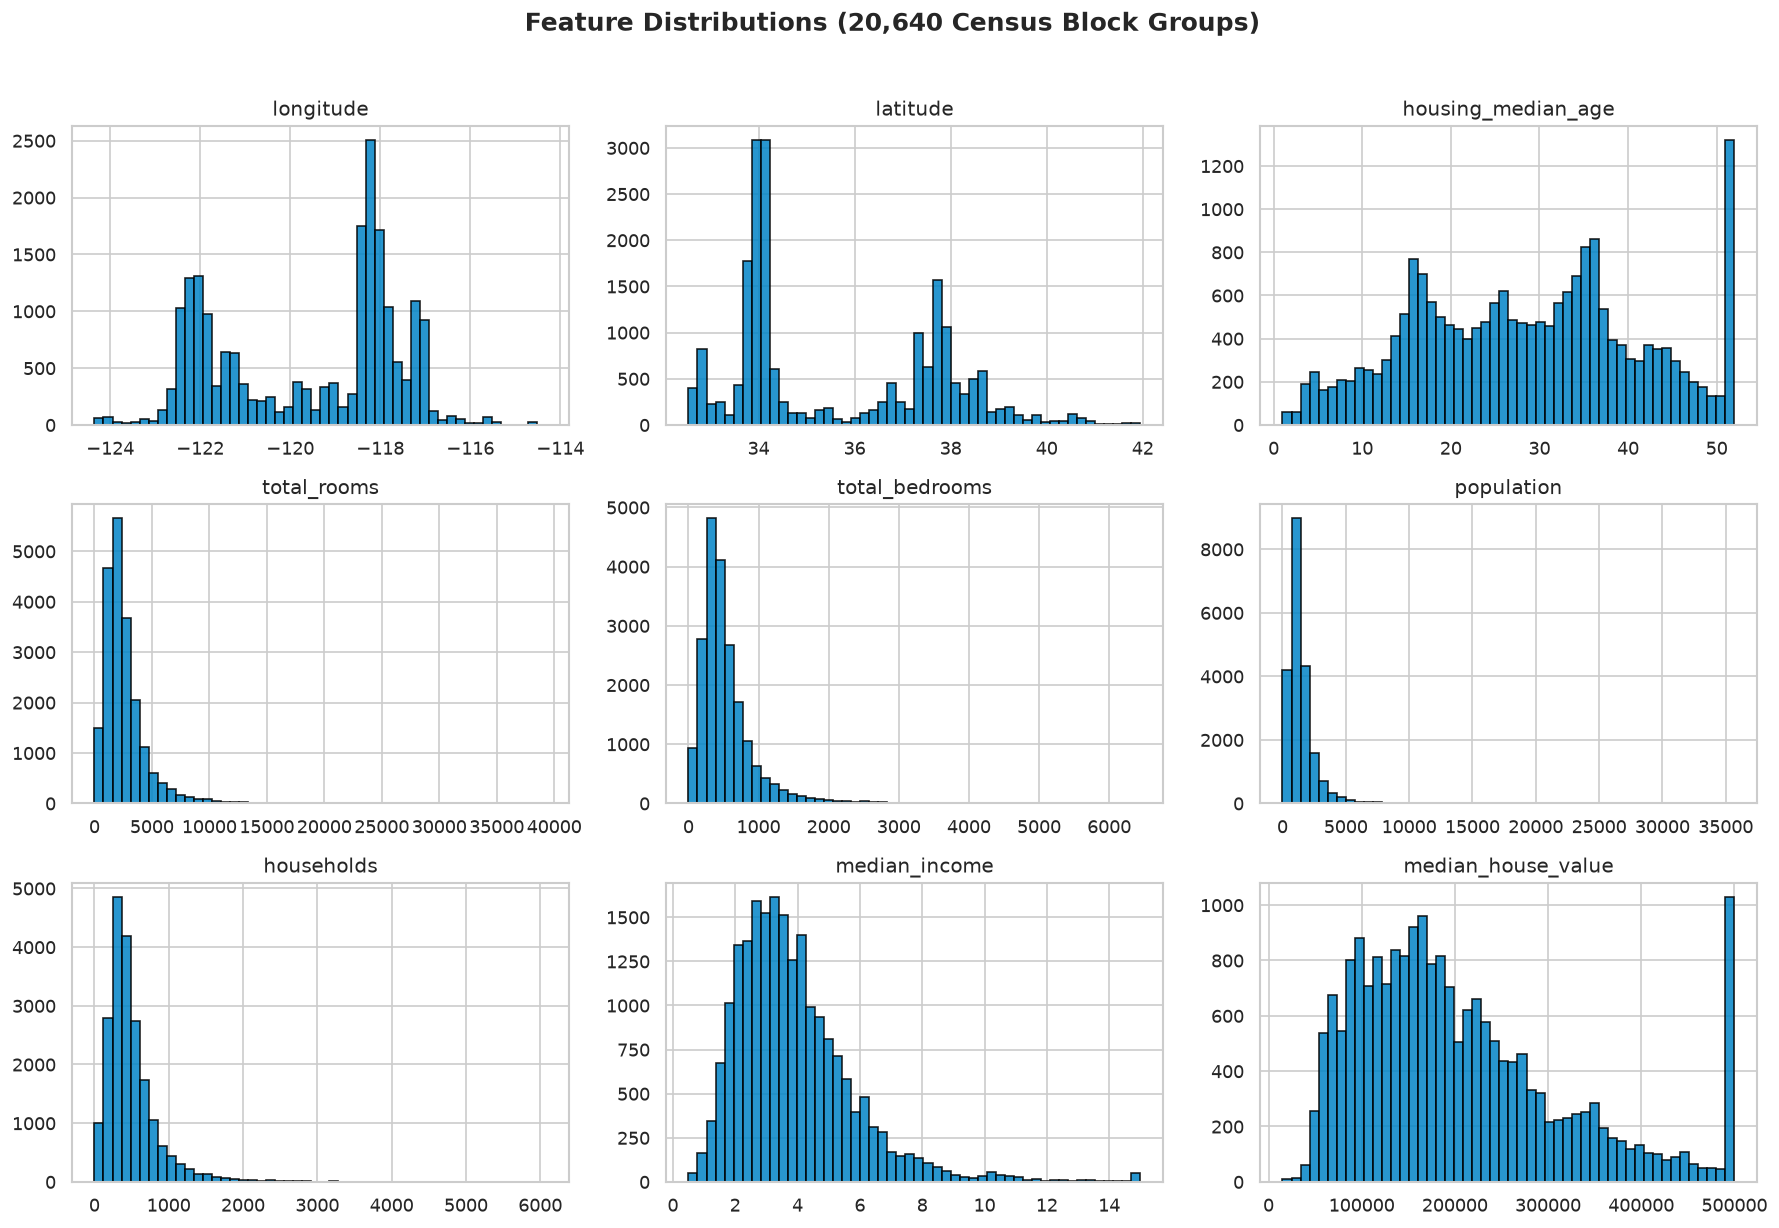

In [7]:
df.hist(bins=50, figsize=(15, 10), color="#0284C7", edgecolor="black", alpha=0.85)
plt.suptitle("Feature Distributions (20,640 Census Block Groups)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 7. Geospatial Analysis: Coordinate Mapping & Spatial Clustering
- **Spatial Scatter Plot**: Maps latitude and longitude coordinates directly recreating California's coastline and cities.
- **Dual Attribute Encoding**: Sizes circle markers by block population and colors points by median house value (`jet` colormap).
- **Regional Price Clusters**: Visually identifies dominant coastal wealth centers (Bay Area, West LA) versus lower-cost Central Valley regions.

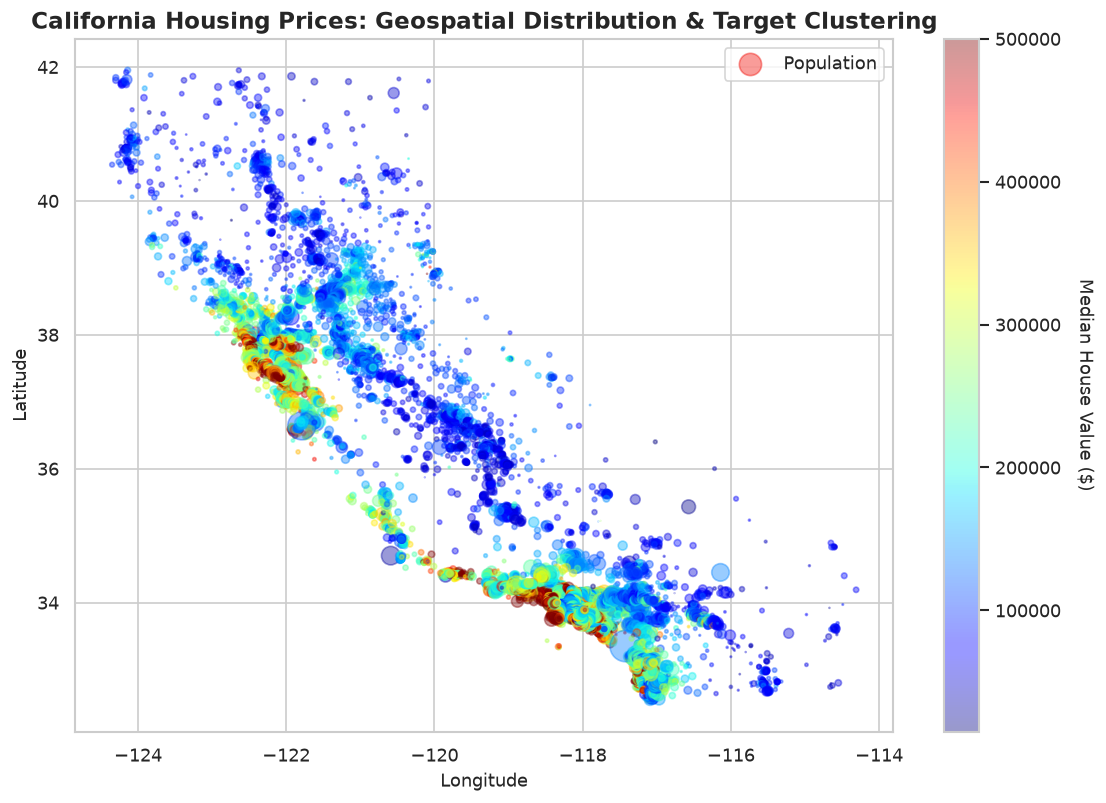

In [8]:
plt.figure(figsize=(11, 7.5))
scatter = plt.scatter(
    df["longitude"],
    df["latitude"],
    alpha=0.4,
    s=df["population"] / 100,
    c=df["median_house_value"],
    cmap="jet",
    label="Population"
)
cbar = plt.colorbar(scatter)
cbar.set_label("Median House Value ($)", rotation=270, labelpad=20, fontsize=11)
plt.title("California Housing Prices: Geospatial Distribution & Target Clustering", fontsize=14, fontweight="bold")
plt.xlabel("Longitude", fontsize=11)
plt.ylabel("Latitude", fontsize=11)
plt.legend(loc="upper right", frameon=True)
plt.show()


## 8. Target Censoring Analysis ($500,001 Ceiling)
- **Censoring Quantification**: Identifies 965 census block groups (4.68% of dataset) artificially clipped at $500,001.
- **Distribution Visual**: Plots target distribution highlighting the right-censored spike at the upper boundary.
- **Modeling Implications**: Notes that standard regression algorithms will systematically under-predict luxury properties due to ceiling compression.

Capped properties (>= $500,001): 965 out of 20,640 (4.68%)


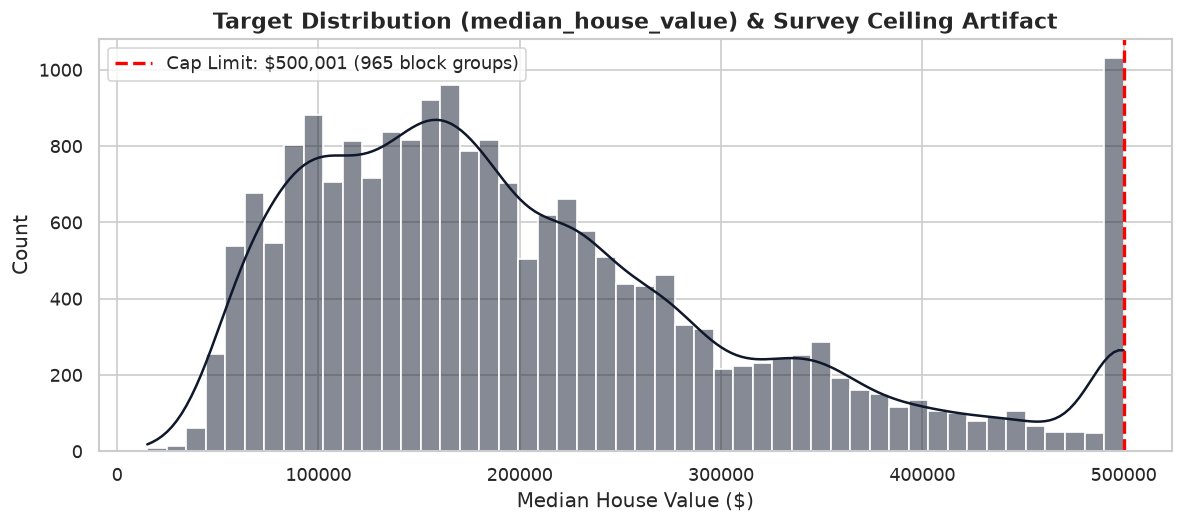

In [9]:
capped_count = (df["median_house_value"] >= 500001).sum()
capped_pct = (capped_count / len(df)) * 100
print(f"Capped properties (>= $500,001): {capped_count:,} out of {len(df):,} ({capped_pct:.2f}%)")

plt.figure(figsize=(10, 4.5))
sns.histplot(df["median_house_value"], bins=50, kde=True, color="#0F172A")
plt.axvline(500001, color="red", linestyle="--", lw=2, label=f"Cap Limit: $500,001 ({capped_count:,} block groups)")
plt.title("Target Distribution (median_house_value) & Survey Ceiling Artifact", fontsize=13, fontweight="bold")
plt.xlabel("Median House Value ($)")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()


## 9. Correlation Structure & Multicollinearity Heatmap
- **Target Correlations**: Computes Pearson correlation coefficients ($r$) against `median_house_value`.
- **Dominant Predictor**: Confirms `median_income` as the strongest linear driver of home values ($r = +0.687$).
- **Multicollinearity Inspection**: Uncovers extreme collinearity ($r > 0.85$) between aggregate room, bedroom, and population counts.

=== Pearson Correlation with Target (median_house_value) ===
  median_house_value       : +1.0000
  median_income            : +0.6881
  total_rooms              : +0.1342
  housing_median_age       : +0.1056
  households               : +0.0658
  total_bedrooms           : +0.0497
  population               : -0.0246
  longitude                : -0.0460
  latitude                 : -0.1442


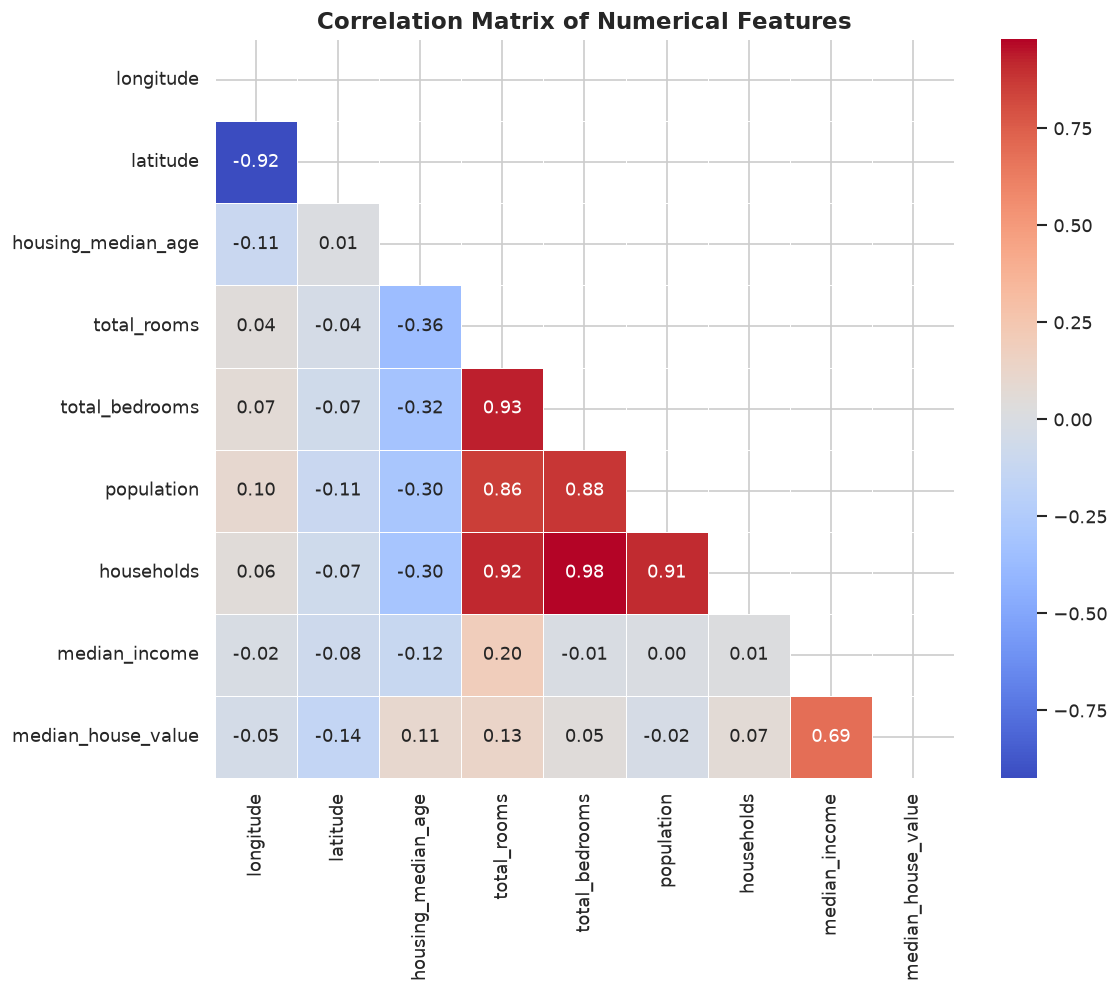

In [10]:
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()
target_corr = corr_matrix["median_house_value"].sort_values(ascending=False)

print("=== Pearson Correlation with Target (median_house_value) ===")
for feat, val in target_corr.items():
    print(f"  {feat:25s}: {val:+.4f}")

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, mask=mask, linewidths=0.5)
plt.title("Correlation Matrix of Numerical Features", fontsize=14, fontweight="bold")
plt.show()


## 10. Domain Feature Engineering & Rationale
- **Ratio Formulation**: Constructs per-household and per-room density ratios (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`).
- **Normalization Impact**: Converts unstandardized block sums into standardized property-level living characteristics.
- **Predictive Gain**: Confirms that `bedrooms_per_room` provides a strong negative correlation ($r = -0.256$) with housing price.

In [11]:
df_eng = df.copy()
df_eng["rooms_per_household"] = df_eng["total_rooms"] / df_eng["households"]
df_eng["bedrooms_per_room"] = df_eng["total_bedrooms"] / df_eng["total_rooms"]
df_eng["population_per_household"] = df_eng["population"] / df_eng["households"]

eng_corrs = df_eng[["rooms_per_household", "bedrooms_per_room", "population_per_household", "median_house_value"]].corr()["median_house_value"]
print("=== Correlations of Engineered Ratios with Target ===")
for feat, val in eng_corrs.items():
    print(f"  {feat:28s}: {val:+.4f}")


=== Correlations of Engineered Ratios with Target ===
  rooms_per_household         : +0.1519
  bedrooms_per_room           : -0.2559
  population_per_household    : -0.0237
  median_house_value          : +1.0000


## 11. Engineering Takeaways & ML Guidelines
- **Key Valuation Drivers**: `median_income` is the primary valuation baseline; room density ratios refine dwelling quality.
- **Non-Linear Geospatial Complexity**: Coastline proximity and spatial coordinates interact non-linearly; tree models and foundation models handle these patterns naturally.
- **Imputation Hygiene**: The 207 missing values in `total_bedrooms` must be imputed strictly using training fold medians to prevent target leakage.
- **Target Clipping Awareness**: Machine learning models will inherently plateau near $500,001 due to right-censoring in the survey data.